## **KECERDASAN ARTIFISIAL UNTUK GEOFISIKA**
### **RECIPE GEOFISIKA: ANALISIS FREKUENSI SINYAL SEISMIK MENGGUNAKAN FFT**

**NAMA:** Azzamakhsary Ramadhani    
**NIM:**    H061251090    
**KELAS:** Kecerdasan Artifisial Untuk Geofisika (Kelas B)

<hr>

#### **Recipe ID: GEO-SEIS-003**
**Bidang:** Geofisika seismik dan pengolahan sinyal  
**Topik:** Analisis kandungan frekuensi sinyal seismik menggunakan Fast Fourier Transform (FFT).

**Petunjuk:** Jalankan sel kode secara berurutan dari atas ke bawah. Notebook ini memakai data sintetik dan tidak memerlukan file lapangan.

**Catatan:** Data dibuat untuk pembelajaran. Hasilnya bukan interpretasi survei seismik nyata.

### **1. Problem — Permasalahan**

Sinyal seismik yang direkam oleh sensor dapat mengandung beberapa komponen frekuensi. Analisis frekuensi membantu mengidentifikasi frekuensi dominan serta melihat perubahan sinyal dari domain waktu ke domain frekuensi.

**Tujuan analisis:**
1. Membuat sinyal seismik sintetik yang terdiri dari beberapa komponen frekuensi dan noise.
2. Memeriksa dan menampilkan sinyal pada domain waktu.
3. Mengubah sinyal ke domain frekuensi menggunakan Fast Fourier Transform (FFT).
4. Menentukan frekuensi dominan sinyal.
5. Membandingkan spektrum sinyal sebelum dan sesudah penyaringan sederhana.
6. Menyimpan data sinyal dan spektrum ke file CSV.

**Batasan:** Sinyal yang digunakan adalah simulasi sederhana. Analisis ini tidak memperhitungkan seluruh karakteristik instrumen, kondisi geologi, atau proses rambat gelombang di bawah permukaan.

## 2. Minimal Theory — Teori Singkat

Sinyal diskret dapat dinyatakan sebagai kumpulan amplitudo $x[n]$ yang direkam pada interval waktu tertentu. Jika frekuensi pencuplikan adalah `$f_s$`, interval waktunya:

$$
\Delta t = \frac{1}{f_s}
$$

Fast Fourier Transform (FFT) digunakan untuk menghitung representasi frekuensi dari sinyal. Secara konseptual, transformasi Fourier memisahkan sinyal menjadi komponen-komponen frekuensi yang menyusunnya.

Resolusi frekuensi bergantung pada lama rekaman (`$T$`):

$$
\Delta f = \frac{1}{T}
$$

Frekuensi dominan adalah frekuensi yang memiliki amplitudo spektrum paling besar pada rentang yang dianalisis. Dalam contoh ini, amplitudo spektrum dihitung dari nilai absolut FFT dan dinormalisasi agar mudah dibandingkan.

### Keterangan

- $x[n]$: amplitudo sinyal pada sampel ke-`$n$`.
- $f_s$: frekuensi pencuplikan dalam satuan Hz.
- $\Delta t$: interval waktu antar-sampel dalam satuan sekon (s).
- $T$: durasi rekaman dalam satuan sekon (s).
- $\Delta f$: resolusi frekuensi dalam satuan Hz.
- $f$: frekuensi dalam satuan Hz.

**Catatan interpretasi:** Puncak spektrum tidak otomatis menunjukkan satu sumber geologi tertentu. Interpretasi data nyata perlu mempertimbangkan instrumen, sumber getaran, *noise*, dan kondisi survei.

### **3. Persiapan — Library yang Digunakan**

Library digunakan untuk membuat data numerik, mengelola tabel, melakukan FFT, dan membuat grafik.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

print("Library berhasil diimpor.")

Library berhasil diimpor.


### **4. Prompt — Instruksi Analisis untuk AI**

*Buat dan analisis sinyal seismik sintetik. Tampilkan sinyal dalam domain waktu, hitung spektrum amplitudo dengan FFT, tentukan frekuensi dominan, lakukan penyaringan frekuensi sederhana untuk demonstrasi, lalu bandingkan sinyal dan spektrumnya. Jelaskan bahwa data bersifat simulasi dan hindari menyimpulkan kondisi geologi nyata dari data sintetik.*

### **5. Code — Membuat Data Sinyal Sintetik**

Sinyal contoh terdiri dari dua komponen sinusoidal dan noise acak. Ubah parameter frekuensi atau tingkat noise untuk melihat dampaknya terhadap spektrum.

In [2]:
# Parameter simulasi
USE_SIMULATED_DATA = True
fs = 200                 # frekuensi pencuplikan (Hz)
duration = 10.0           # durasi rekaman (detik)
t = np.arange(0, duration, 1/fs)

# Sinyal sintetik: dua komponen frekuensi + noise
rng = np.random.default_rng(42)
f1, f2 = 8.0, 25.0        # frekuensi komponen (Hz)
signal_clean = (
    1.0 * np.sin(2 * np.pi * f1 * t)
    + 0.45 * np.sin(2 * np.pi * f2 * t)
)
noise = 0.35 * rng.normal(size=len(t))
signal = signal_clean + noise

df_signal = pd.DataFrame({
    "Time_s": t,
    "Amplitude": signal,
    "CleanSignal": signal_clean,
    "Noise": noise
})

print("Sumber data: SIMULASI")
print(f"Jumlah sampel: {len(df_signal)}")
print(f"Frekuensi pencuplikan: {fs} Hz")
display(df_signal.head())

Sumber data: SIMULASI
Jumlah sampel: 2000
Frekuensi pencuplikan: 200 Hz


,Time_s,Amplitude,CleanSignal,Noise
0,0.000,0.106651,0.000000,0.106651
1,0.005,0.202894,0.566888,-0.363994
2,0.010,1.194412,0.931754,0.262658
3,0.015,1.331943,1.002745,0.329198
4,0.020,0.161466,0.844328,-0.682862


### **6. Pemeriksaan dan Visualisasi Domain Waktu**

Grafik berikut menunjukkan amplitudo sinyal terhadap waktu. Noise membuat sinyal terukur berbeda dari sinyal dasar yang dibentuk dalam simulasi.

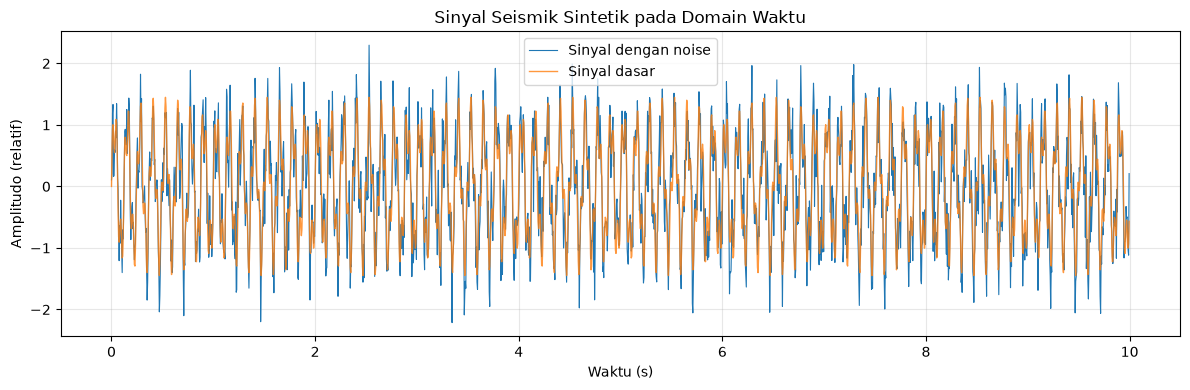

In [3]:
plt.figure(figsize=(12, 4))
plt.plot(t, signal, label="Sinyal dengan noise", linewidth=0.8)
plt.plot(t, signal_clean, label="Sinyal dasar", alpha=0.8, linewidth=1)
plt.xlabel("Waktu (s)")
plt.ylabel("Amplitudo (relatif)")
plt.title("Sinyal Seismik Sintetik pada Domain Waktu")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### **7. Code — Menghitung Spektrum dengan FFT**

Spektrum satu sisi ditampilkan untuk frekuensi non-negatif. Komponen frekuensi dominan dicari dengan mengabaikan komponen 0 Hz (DC).

In [4]:
N = len(signal)
fft_values = np.fft.rfft(signal)
freq = np.fft.rfftfreq(N, d=1/fs)

# Normalisasi amplitudo spektrum satu sisi
amplitude_spectrum = np.abs(fft_values) * 2 / N
amplitude_spectrum[0] = amplitude_spectrum[0] / 2
if N % 2 == 0:
    amplitude_spectrum[-1] = amplitude_spectrum[-1] / 2

# Cari frekuensi dominan selain 0 Hz
valid = freq > 0
dominant_index = np.argmax(amplitude_spectrum[valid])
dominant_frequency = freq[valid][dominant_index]
dominant_amplitude = amplitude_spectrum[valid][dominant_index]

print(f"Frekuensi dominan: {dominant_frequency:.2f} Hz")
print(f"Amplitudo spektrum pada puncak: {dominant_amplitude:.3f}")

Frekuensi dominan: 8.00 Hz
Amplitudo spektrum pada puncak: 1.011


### **8. Visualisasi Domain Frekuensi**

Puncak spektrum memperlihatkan frekuensi yang relatif kuat dalam sinyal. Karena ada noise, puncak terbesar dapat sedikit berubah dibandingkan frekuensi yang digunakan saat membangun sinyal.

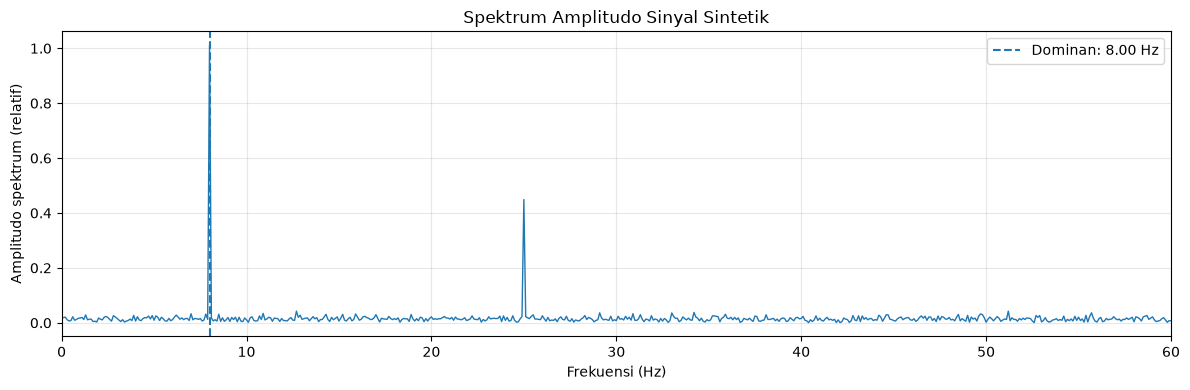

In [5]:
plt.figure(figsize=(12, 4))
plt.plot(freq, amplitude_spectrum, linewidth=1)
plt.axvline(dominant_frequency, linestyle="--",
            label=f"Dominan: {dominant_frequency:.2f} Hz")
plt.xlim(0, 60)
plt.xlabel("Frekuensi (Hz)")
plt.ylabel("Amplitudo spektrum (relatif)")
plt.title("Spektrum Amplitudo Sinyal Sintetik")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### **9. Code — Penyaringan Frekuensi Sederhana**

Sebagai demonstrasi, komponen frekuensi di atas 15 Hz dihilangkan pada domain FFT, lalu sinyal dikembalikan ke domain waktu dengan inverse FFT. Ini hanya contoh pemrosesan; pemilihan filter untuk data nyata harus disesuaikan dengan tujuan analisis.

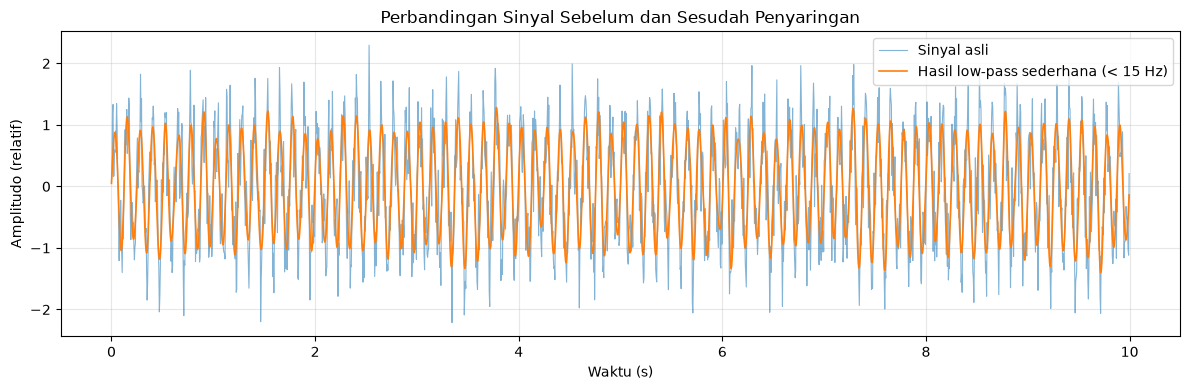

In [6]:
cutoff_hz = 15.0
filtered_fft = fft_values.copy()
filtered_fft[freq > cutoff_hz] = 0
filtered_signal = np.fft.irfft(filtered_fft, n=N)

plt.figure(figsize=(12, 4))
plt.plot(t, signal, label="Sinyal asli", alpha=0.55, linewidth=0.8)
plt.plot(t, filtered_signal, label=f"Hasil low-pass sederhana (< {cutoff_hz:g} Hz)",
         linewidth=1.2)
plt.xlabel("Waktu (s)")
plt.ylabel("Amplitudo (relatif)")
plt.title("Perbandingan Sinyal Sebelum dan Sesudah Penyaringan")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### **10. Ringkasan Hasil dan Ekspor CSV**

Dua file CSV dibuat: data sinyal pada domain waktu dan spektrum amplitudo. File disimpan di folder kerja notebook.

In [7]:
df_spectrum = pd.DataFrame({
    "Frequency_Hz": freq,
    "AmplitudeSpectrum": amplitude_spectrum
})

summary = pd.DataFrame([{
    "SamplingFrequency_Hz": fs,
    "Duration_s": duration,
    "NumberOfSamples": N,
    "DominantFrequency_Hz": dominant_frequency,
    "DominantAmplitude": dominant_amplitude,
    "LowPassCutoff_Hz": cutoff_hz
}])

output_dir = Path("hasil_analisis_fft")
output_dir.mkdir(exist_ok=True)

df_signal.to_csv(output_dir / "sinyal_sintetik.csv", index=False)
df_spectrum.to_csv(output_dir / "spektrum_fft.csv", index=False)
summary.to_csv(output_dir / "ringkasan_hasil.csv", index=False)

display(summary)
print(f"File hasil disimpan di: {output_dir.resolve()}")

,SamplingFrequency_Hz,Duration_s,NumberOfSamples,DominantFrequency_Hz,DominantAmplitude,LowPassCutoff_Hz
0,200,10.0,2000,8.0,1.011265,15.0


File hasil disimpan di: C:\Users\user\Downloads\hasil_analisis_fft


## 12. Result — Hasil dan Interpretasi

Setelah semua sel kode dijalankan, amati grafik sinyal seismik terhadap waktu, spektrum frekuensi hasil Fast Fourier Transform (FFT), nilai frekuensi dominan, serta perbandingan sinyal sebelum dan sesudah penyaringan frekuensi.

- Grafik domain waktu menunjukkan perubahan amplitudo sinyal seismik terhadap waktu.
- Spektrum frekuensi hasil FFT digunakan untuk mengidentifikasi komponen frekuensi yang terdapat dalam sinyal.
- Frekuensi dominan ditentukan berdasarkan puncak amplitudo pada spektrum frekuensi.
- Penyaringan frekuensi sederhana digunakan untuk mengamati perubahan sinyal setelah komponen frekuensi tertentu dikurangi atau dihilangkan.
- Perbedaan antara sinyal awal dan sinyal hasil penyaringan menunjukkan pengaruh pemilihan rentang frekuensi terhadap bentuk sinyal.
- Karena data yang digunakan merupakan data simulasi, hasil analisis hanya digunakan untuk pembelajaran dan tidak secara langsung menggambarkan kondisi geologi di lokasi nyata.

## 13. Optional Check — Checklist Kualitas

- Kolom waktu dan amplitudo tersedia dan memiliki jumlah data yang sesuai.
- Tidak terdapat nilai kosong atau nilai nonnumerik pada data yang digunakan.
- Interval waktu pengambilan sampel bernilai positif dan konsisten.
- Frekuensi sampling ditentukan berdasarkan interval waktu pengambilan sampel.
- Spektrum frekuensi dihitung menggunakan FFT dengan parameter yang sesuai.
- Frekuensi dominan ditentukan berdasarkan puncak spektrum yang relevan.
- Grafik sinyal pada domain waktu dan grafik spektrum frekuensi ditampilkan dengan label sumbu dan satuan yang sesuai.
- Hasil penyaringan frekuensi diperiksa dengan membandingkannya terhadap sinyal awal.
- Data simulasi dinyatakan dengan jelas agar tidak disalahartikan sebagai data pengukuran lapangan.

## 14. Kesimpulan

Recipe GEO-SEIS-003 menyediakan alur kerja dasar analisis frekuensi sinyal seismik menggunakan Fast Fourier Transform (FFT), mulai dari pembuatan dan pemeriksaan data sintetik, visualisasi sinyal pada domain waktu, perhitungan spektrum frekuensi, penentuan frekuensi dominan, hingga penyaringan frekuensi dan penyimpanan hasil analisis. Metode FFT membantu mengidentifikasi komponen frekuensi yang terkandung dalam sinyal seismik, sedangkan penyaringan frekuensi memberikan gambaran mengenai pengaruh komponen frekuensi tertentu terhadap bentuk sinyal. Hasil analisis bergantung pada karakteristik data, interval sampling, dan parameter pemrosesan yang digunakan. Oleh karena itu, hasil dari data simulasi ini perlu dipahami sebagai latihan analisis dan tidak dapat langsung digunakan untuk menyimpulkan kondisi bawah permukaan tanpa data lapangan dan interpretasi geofisika lebih lanjut.